# 03 — Exploratory Data Analysis

Explore hourly PM2.5 in Hanoi, temporal patterns, and relationships with meteorological and pollutant predictors of the **6-hour-ahead target**.

**Input:** `../data/processed/hanoi_pm25_model_withna.pkl` from Notebook 02. Missing values are retained for EDA.

In [21]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns

PROCESSED_DIR = Path("../data/processed")
df_model = pd.read_pickle(PROCESSED_DIR / "hanoi_pm25_model_withna.pkl")

## 1. PM2.5 distribution

In [22]:
df_model["pm25"].describe()

count    8082.000000
mean       42.052914
std        34.396470
min         1.000000
25%        19.700000
50%        32.300000
75%        53.100000
max       249.000000
Name: pm25, dtype: float64

In [23]:
df_model["pm25"].skew()

np.float64(1.985931727962026)

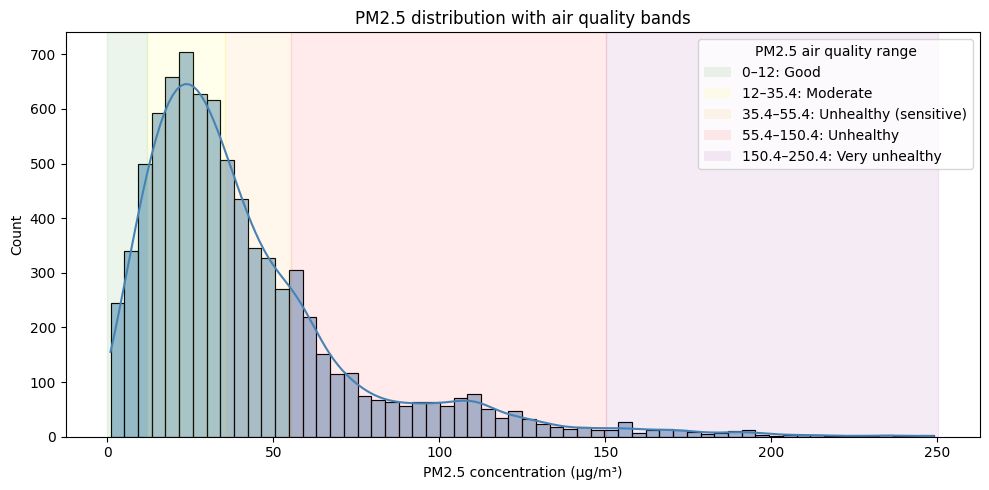

In [24]:
bands = [
    (0, 12, 'green', 'Good'),
    (12, 35.4, 'yellow', 'Moderate'),
    (35.4, 55.4, 'orange', 'Unhealthy (sensitive)'),
    (55.4, 150.4, 'red', 'Unhealthy'),
    (150.4, 250.4, 'purple', 'Very unhealthy'),
]

fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(df_model['pm25'], bins=60, kde=True, ax=ax, color='steelblue')

for lo, hi, color, label in bands:
    ax.axvspan(lo, hi, color=color, alpha=0.08)

legend_handles = [
    Patch(facecolor=color, alpha=0.08, label=f'{lo}–{hi}: {label}')
    for lo, hi, color, label in bands
]

ax.legend(
    handles=legend_handles,
    title='PM2.5 air quality range'
)

ax.set_title('PM2.5 distribution with air quality bands')
ax.set_xlabel('PM2.5 concentration (µg/m³)')
ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

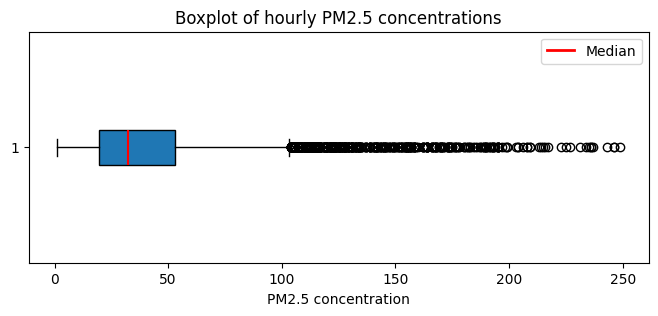

In [25]:
plt.figure(figsize=(8, 3))

bp = plt.boxplot(
    df_model["pm25"].dropna(),
    vert=False,
    medianprops={"color": "red", "linewidth": 1.5},
    patch_artist=True
)

median_line = Line2D([0], [0], color=bp["medians"][0].get_color(), lw=2)
plt.legend([median_line], ["Median"], loc="best")

plt.xlabel("PM2.5 concentration")
plt.title("Boxplot of hourly PM2.5 concentrations")
plt.show()

**Finding:** PM2.5 is right-skewed; high readings are retained as potential pollution episodes, not automatically classified as errors.

## 2. Temporal and monthly patterns

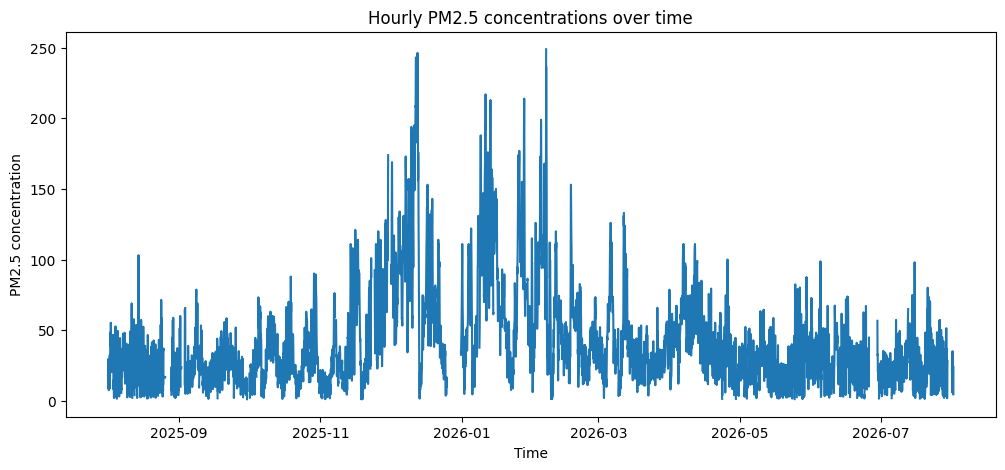

In [26]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_model["timestamp_local"],
    df_model["pm25"]
)

plt.xlabel("Time")
plt.ylabel("PM2.5 concentration")
plt.title("Hourly PM2.5 concentrations over time")

plt.show()

In [27]:
daily_mean = (
    df_model.set_index("timestamp_local")["pm25"].resample("D").mean()
)
daily_count = (
    df_model.set_index("timestamp_local")["pm25"].resample("D").count()
)

daily_pm25 = pd.DataFrame({
    "pm25_mean": daily_mean,
    "observed_hours": daily_count,
})

# Plot daily means only when at least 18 hourly readings are observed.
daily_pm25_valid = daily_pm25[daily_pm25["observed_hours"] >= 18].copy()
daily_pm25["pm25_mean_valid"] = daily_pm25["pm25_mean"].where(
    daily_pm25["observed_hours"] >= 18
)

print("Total days:", len(daily_pm25))
print("Valid days:", len(daily_pm25_valid))
print("Excluded days:", len(daily_pm25) - len(daily_pm25_valid))

Total days: 366
Valid days: 335
Excluded days: 31


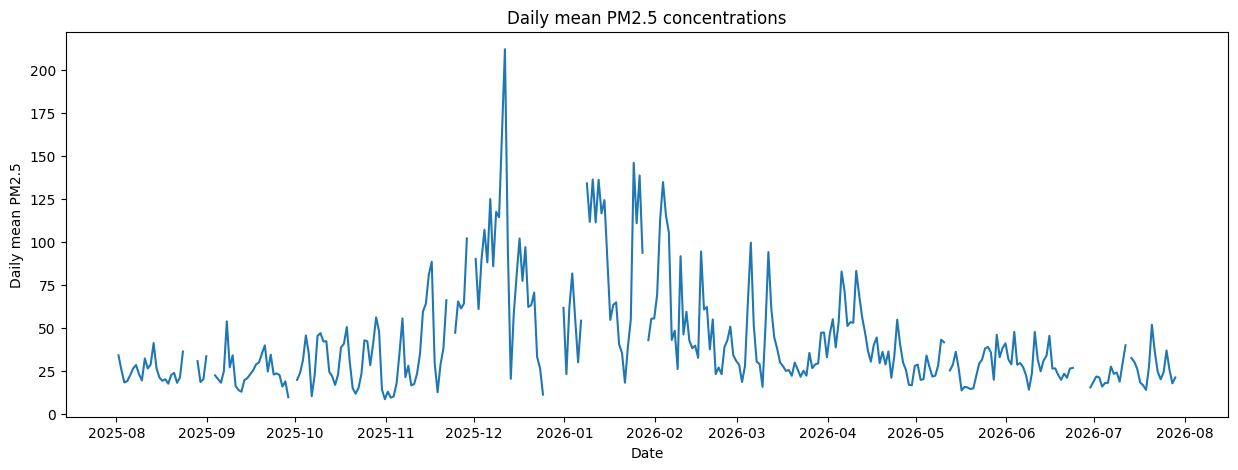

In [28]:
plt.figure(figsize=(15, 5))

plt.plot(
    daily_pm25.index,
    daily_pm25["pm25_mean_valid"]
)

plt.xlabel("Date")
plt.ylabel("Daily mean PM2.5")
plt.title("Daily mean PM2.5 concentrations")

ax = plt.gca()

ax.xaxis.set_major_locator(
    mdates.MonthLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m")
)

plt.xticks(rotation=0)

plt.show()

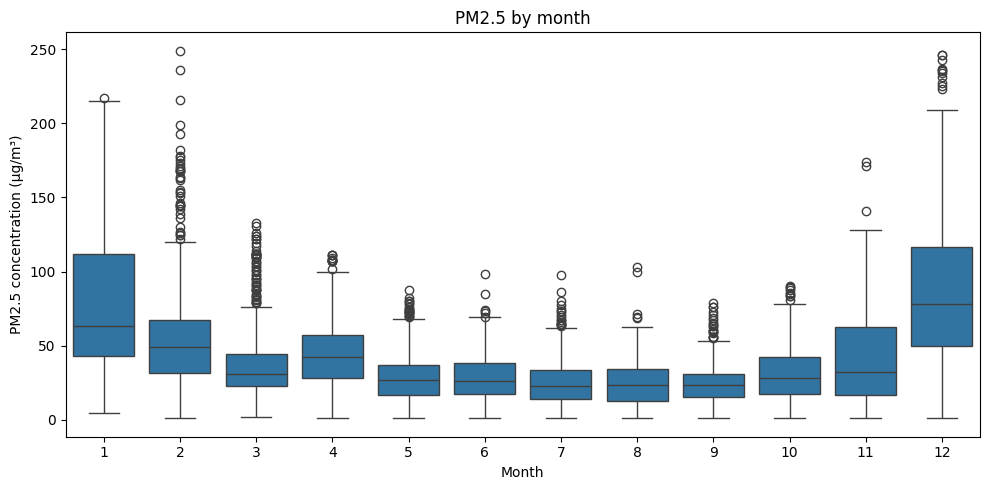

In [29]:
# Create month variable if it does not already exist
df_model['month'] = df_model['timestamp_utc'].dt.month

plt.figure(figsize=(10, 5))

sns.boxplot(
    x='month',
    y='pm25',
    data=df_model
)

plt.title('PM2.5 by month')
plt.xlabel('Month')
plt.ylabel('PM2.5 concentration (µg/m³)')

plt.tight_layout()
plt.show()

## 3. Diurnal pattern (local time)

In [30]:
df_model["hour_local"] = df_model["timestamp_local"].dt.hour

hourly_pattern = (
    df_model.groupby("hour_local")["pm25"].agg(["mean", "median", "count"])
)

hourly_pattern

,mean,median,count
hour_local,,,
0,48.229125,35.30,343
1,44.141735,32.25,340
2,40.546029,30.35,340
3,40.114970,29.15,334
4,43.187553,32.40,331
5,44.109587,30.90,339
6,45.203521,32.15,338
7,44.093283,32.10,332
8,41.629852,31.75,338


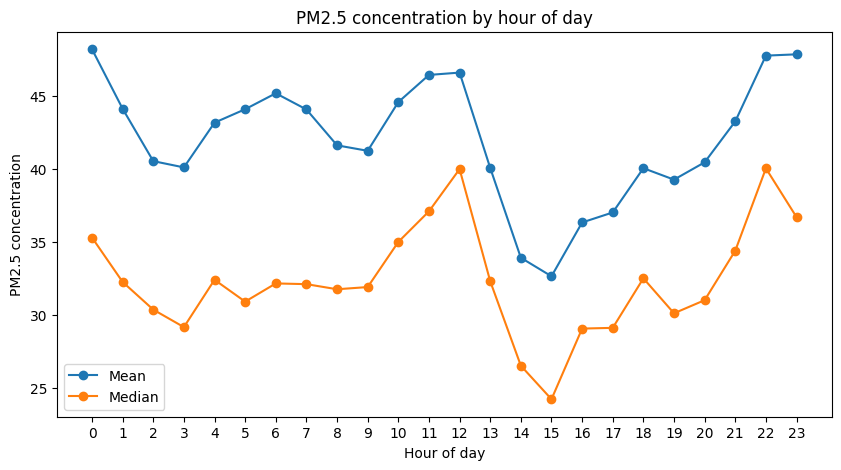

In [31]:
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_pattern.index,
    hourly_pattern["mean"],
    marker="o",
    label="Mean"
)

plt.plot(
    hourly_pattern.index,
    hourly_pattern["median"],
    marker="o",
    label="Median"
)

plt.xlabel("Hour of day")
plt.ylabel("PM2.5 concentration")
plt.title("PM2.5 concentration by hour of day")

plt.xticks(range(24))
plt.legend()

plt.show()

## 4. Correlations with PM2.5 and the t+6 target

In [32]:
predictor_cols = [
    "pm10",
    "no2",
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "surface_pressure",
    "wind_speed_10m",
    "wind_dir_sin",
    "wind_dir_cos"
]

predictor_corr = (
    df_model[["pm25"] + predictor_cols]
    .corr()["pm25"]
    .drop("pm25")
    .sort_values()
)

predictor_corr

temperature_2m         -0.367158
wind_speed_10m         -0.239365
precipitation          -0.111713
relative_humidity_2m   -0.014003
wind_dir_sin            0.019052
wind_dir_cos            0.034208
no2                     0.339292
surface_pressure        0.381960
pm10                    0.965683
Name: pm25, dtype: float64

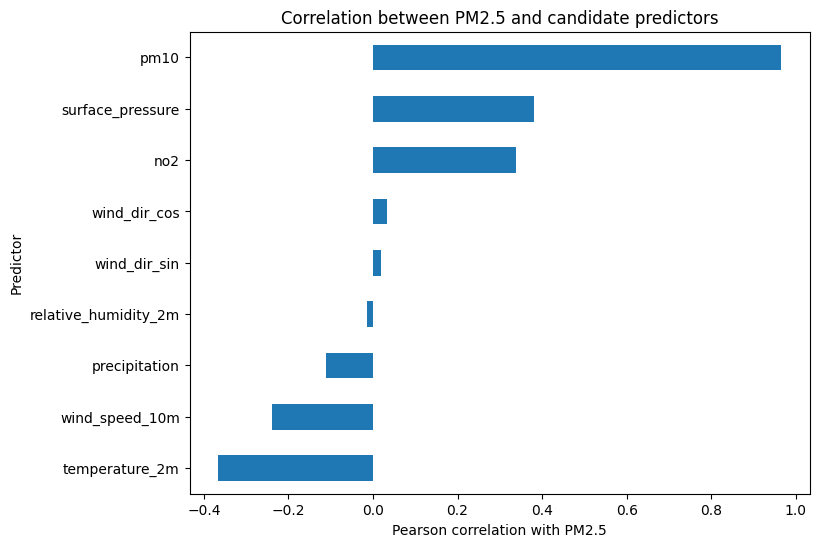

In [33]:
plt.figure(figsize=(8, 6))

predictor_corr.plot(kind="barh")

plt.xlabel("Pearson correlation with PM2.5")
plt.ylabel("Predictor")
plt.title("Correlation between PM2.5 and candidate predictors")

plt.show()

In [34]:
predictor_cols = [
    "pm25",
    "pm25_lag1",
    "pm25_lag2",
    "pm25_lag3",
    "pm25_lag6",
    "pm10",
    "no2",
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "surface_pressure",
    "wind_speed_10m",
    "wind_dir_sin",
    "wind_dir_cos",
    "hour_sin",
    "hour_cos"
]

target_corr = (
    df_model[predictor_cols + ["pm25_t_plus_6"]]
    .corr()["pm25_t_plus_6"]
    .drop("pm25_t_plus_6")
    .sort_values()
)

target_corr

temperature_2m         -0.366423
wind_speed_10m         -0.321017
precipitation          -0.128964
relative_humidity_2m   -0.070946
hour_sin               -0.043325
wind_dir_cos           -0.003020
wind_dir_sin            0.024078
hour_cos                0.051635
no2                     0.330896
surface_pressure        0.363186
pm25_lag6               0.647672
pm25_lag3               0.659994
pm25_lag2               0.686114
pm25_lag1               0.724328
pm25                    0.763581
pm10                    0.769882
Name: pm25_t_plus_6, dtype: float64

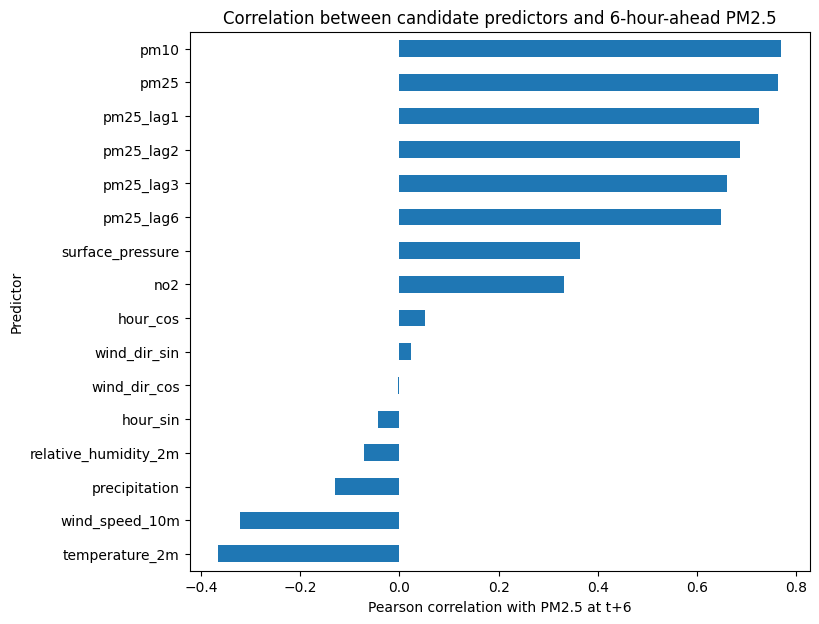

In [35]:
plt.figure(figsize=(8, 7))

target_corr.plot(kind="barh")

plt.xlabel("Pearson correlation with PM2.5 at t+6")
plt.ylabel("Predictor")
plt.title("Correlation between candidate predictors and 6-hour-ahead PM2.5")

plt.show()

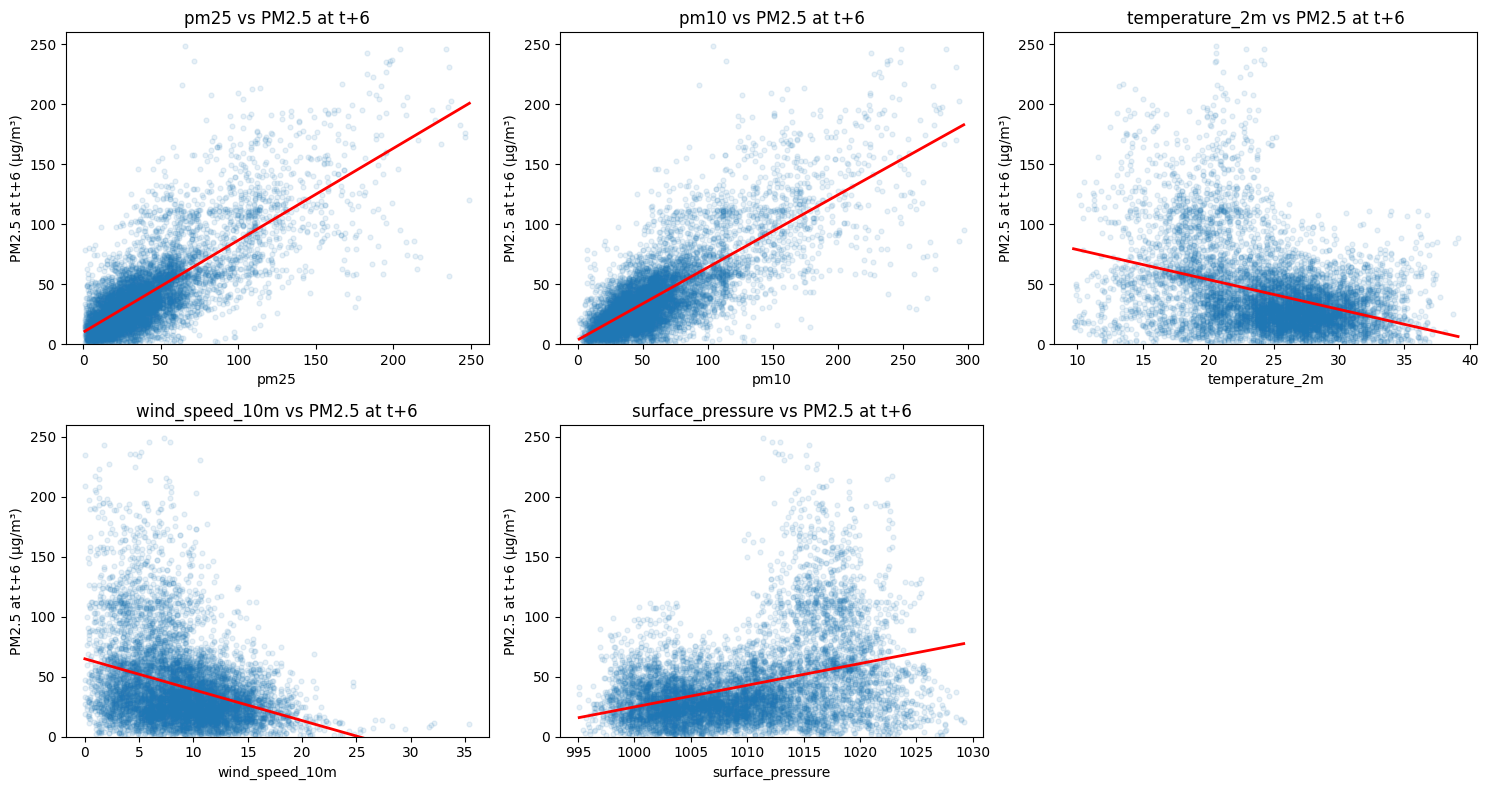

In [36]:
scatter_vars = [
    "pm25",
    "pm10",
    "temperature_2m",
    "wind_speed_10m",
    "surface_pressure"
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(15, 8)
)

axes = axes.flatten()

for ax, col in zip(axes, scatter_vars):
    
    plot_data = df_model[[col, "pm25_t_plus_6"]].dropna()
    
    x = plot_data[col]
    y = plot_data["pm25_t_plus_6"]
    
    # Scatter points
    ax.scatter(
        x,
        y,
        alpha=0.1,
        s=12
    )
    
    # Linear regression line
    slope, intercept = np.polyfit(x, y, 1)
    
    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = slope * x_line + intercept
    
    ax.plot(
        x_line,
        y_line,
        color="red",
        linewidth=2
    )
    
    ax.set_xlabel(col)
    ax.set_ylabel("PM2.5 at t+6 (µg/m³)")
    ax.set_title(f"{col} vs PM2.5 at t+6")
    ax.set_ylim(0, 260)

# Remove unused subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

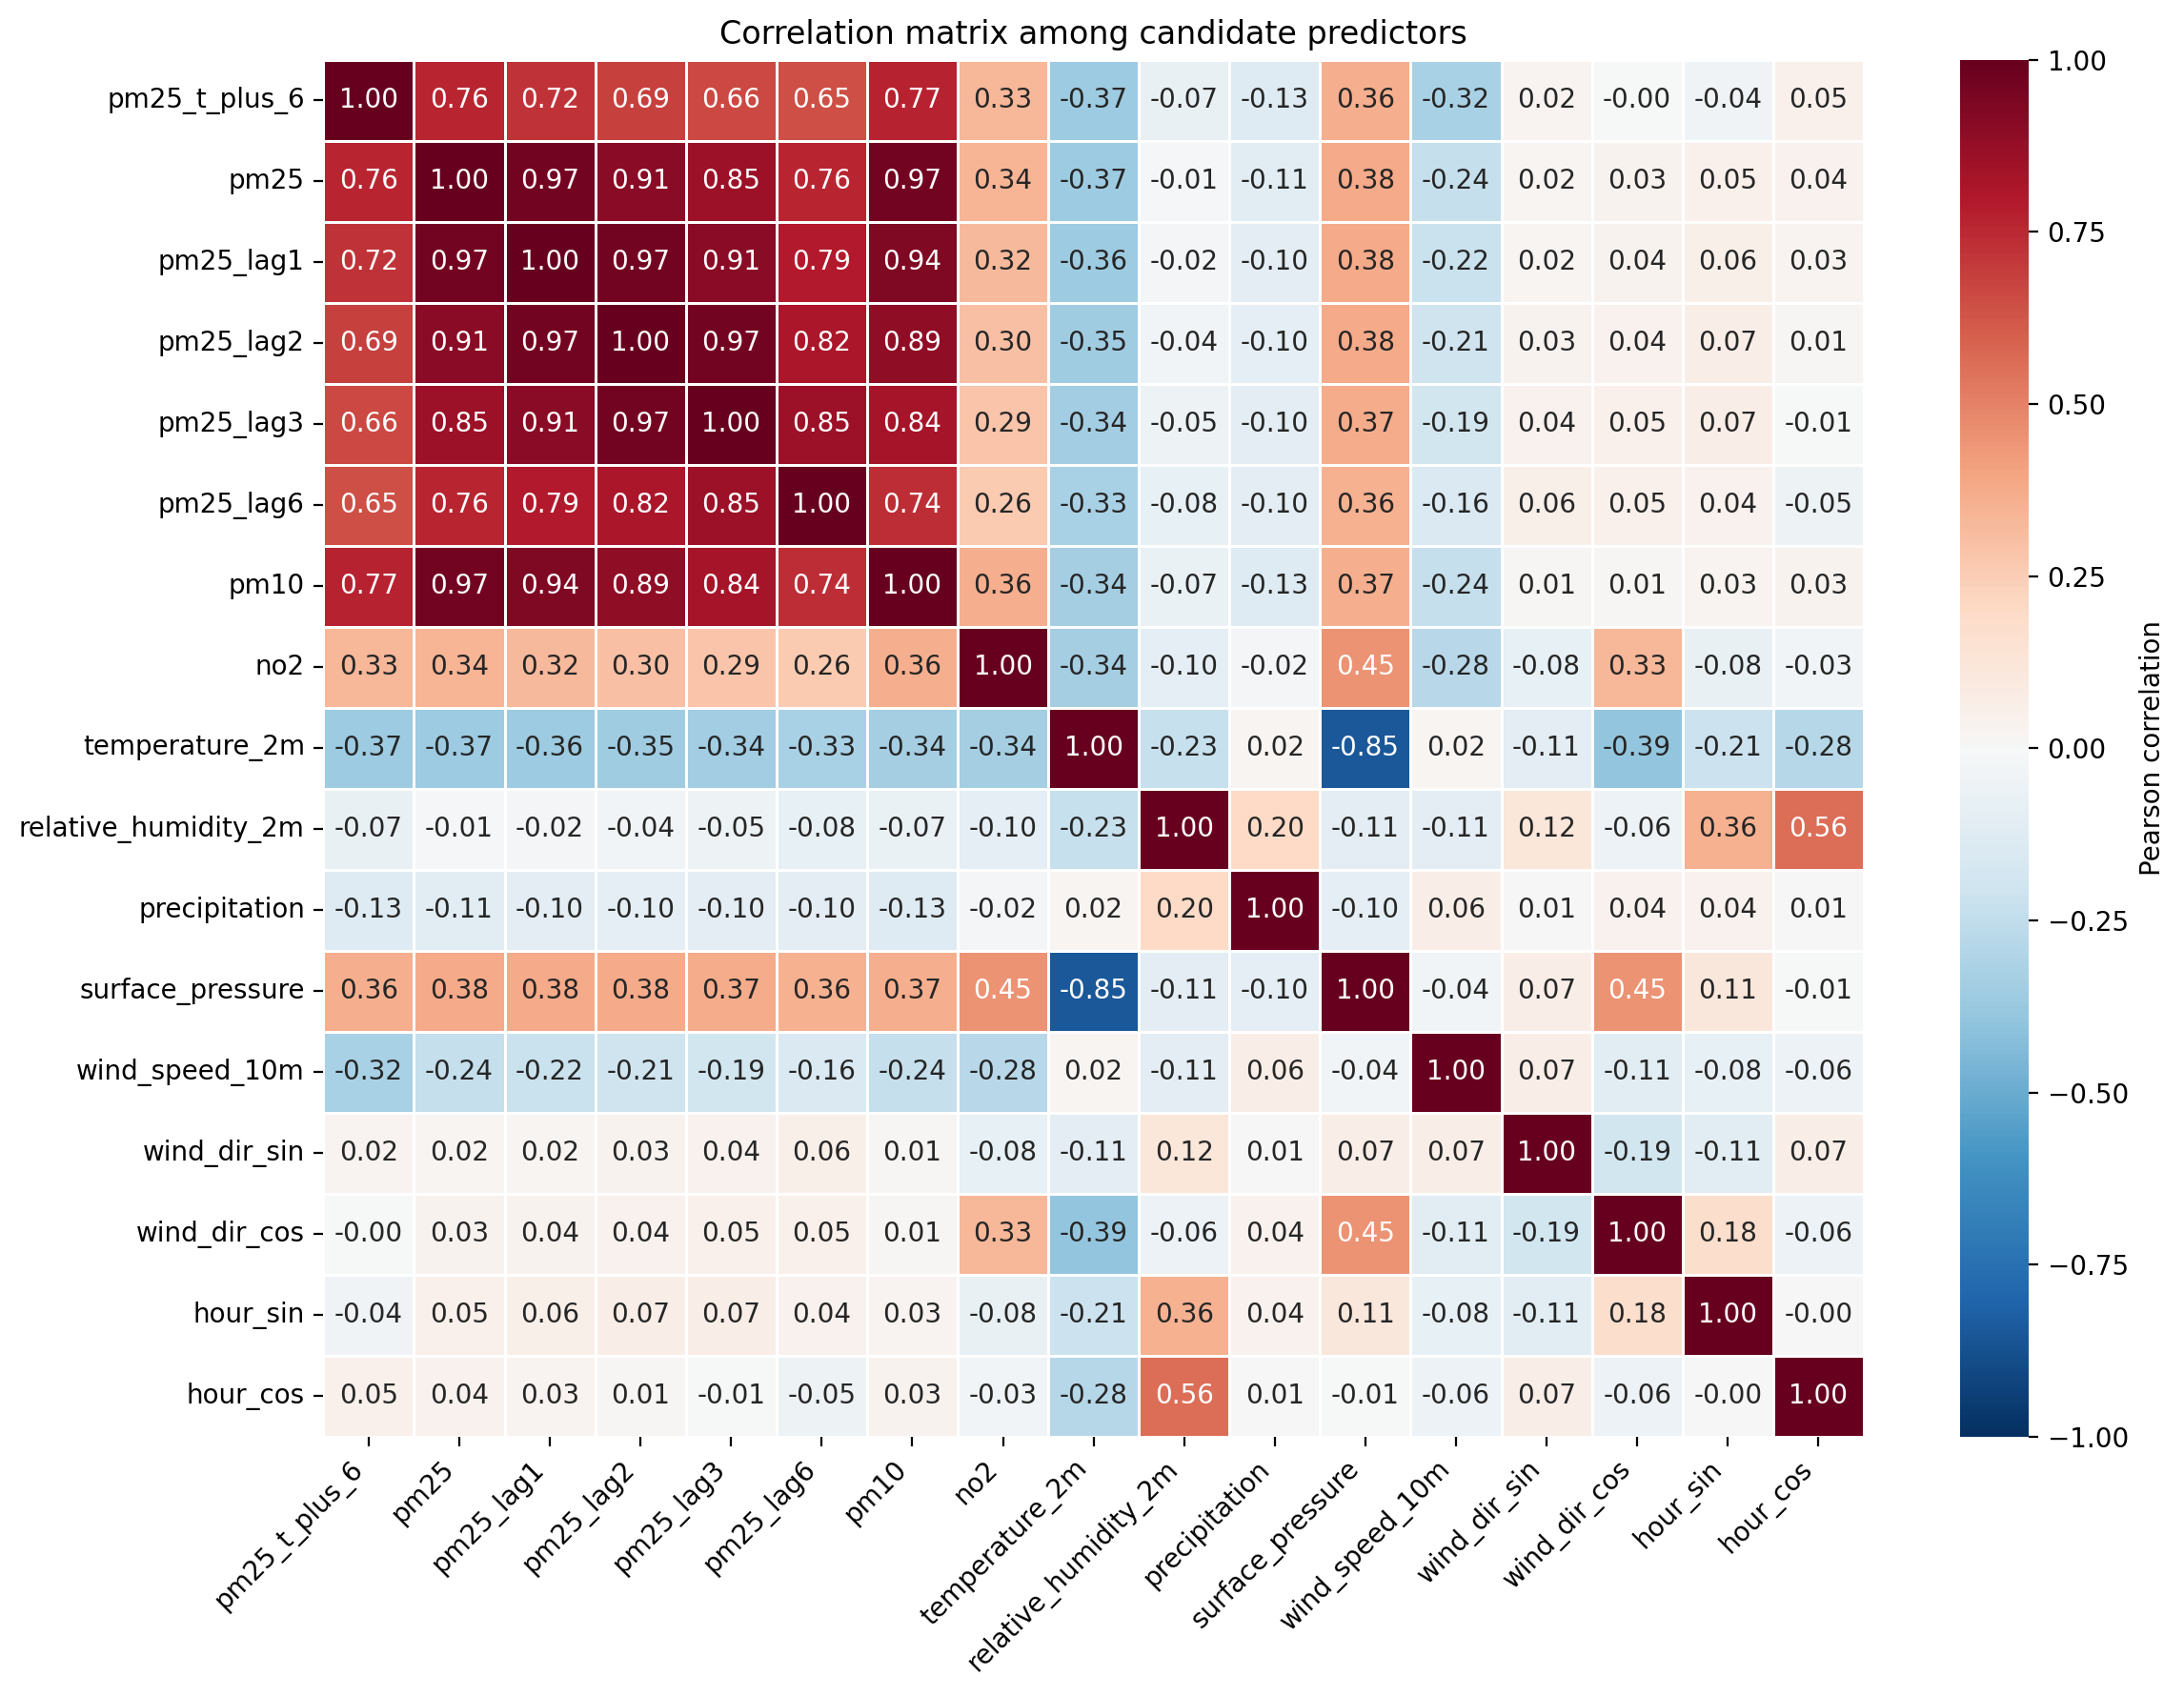

In [37]:
selected_predictors = [
    "pm25_t_plus_6", "pm25", "pm25_lag1", "pm25_lag2",
    "pm25_lag3", "pm25_lag6", "pm10", "no2",
    "temperature_2m", "relative_humidity_2m", "precipitation",
    "surface_pressure", "wind_speed_10m", "wind_dir_sin",
    "wind_dir_cos", "hour_sin", "hour_cos",
]

corr_matrix = df_model[selected_predictors].corr()

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)
plt.figure(figsize=(12, 9), dpi=200)
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Pearson correlation"},
)
plt.title("Correlation matrix among candidate predictors")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "predictor_corr.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Daily PM2.5 and meteorological conditions

In [38]:
daily_eda = (
    df_model
    .set_index("timestamp_local")
    .resample("D")
    .agg(
        pm25_mean=("pm25", "mean"),
        pm25_count=("pm25", "count"),
        temperature_mean=("temperature_2m", "mean"),
        wind_speed_mean=("wind_speed_10m", "mean"),
        surface_pressure_mean=("surface_pressure", "mean"),
        precipitation_total=("precipitation", "sum"),
    )
)

daily_eda["pm25_mean_valid"] = daily_eda["pm25_mean"].where(
    daily_eda["pm25_count"] >= 18
)

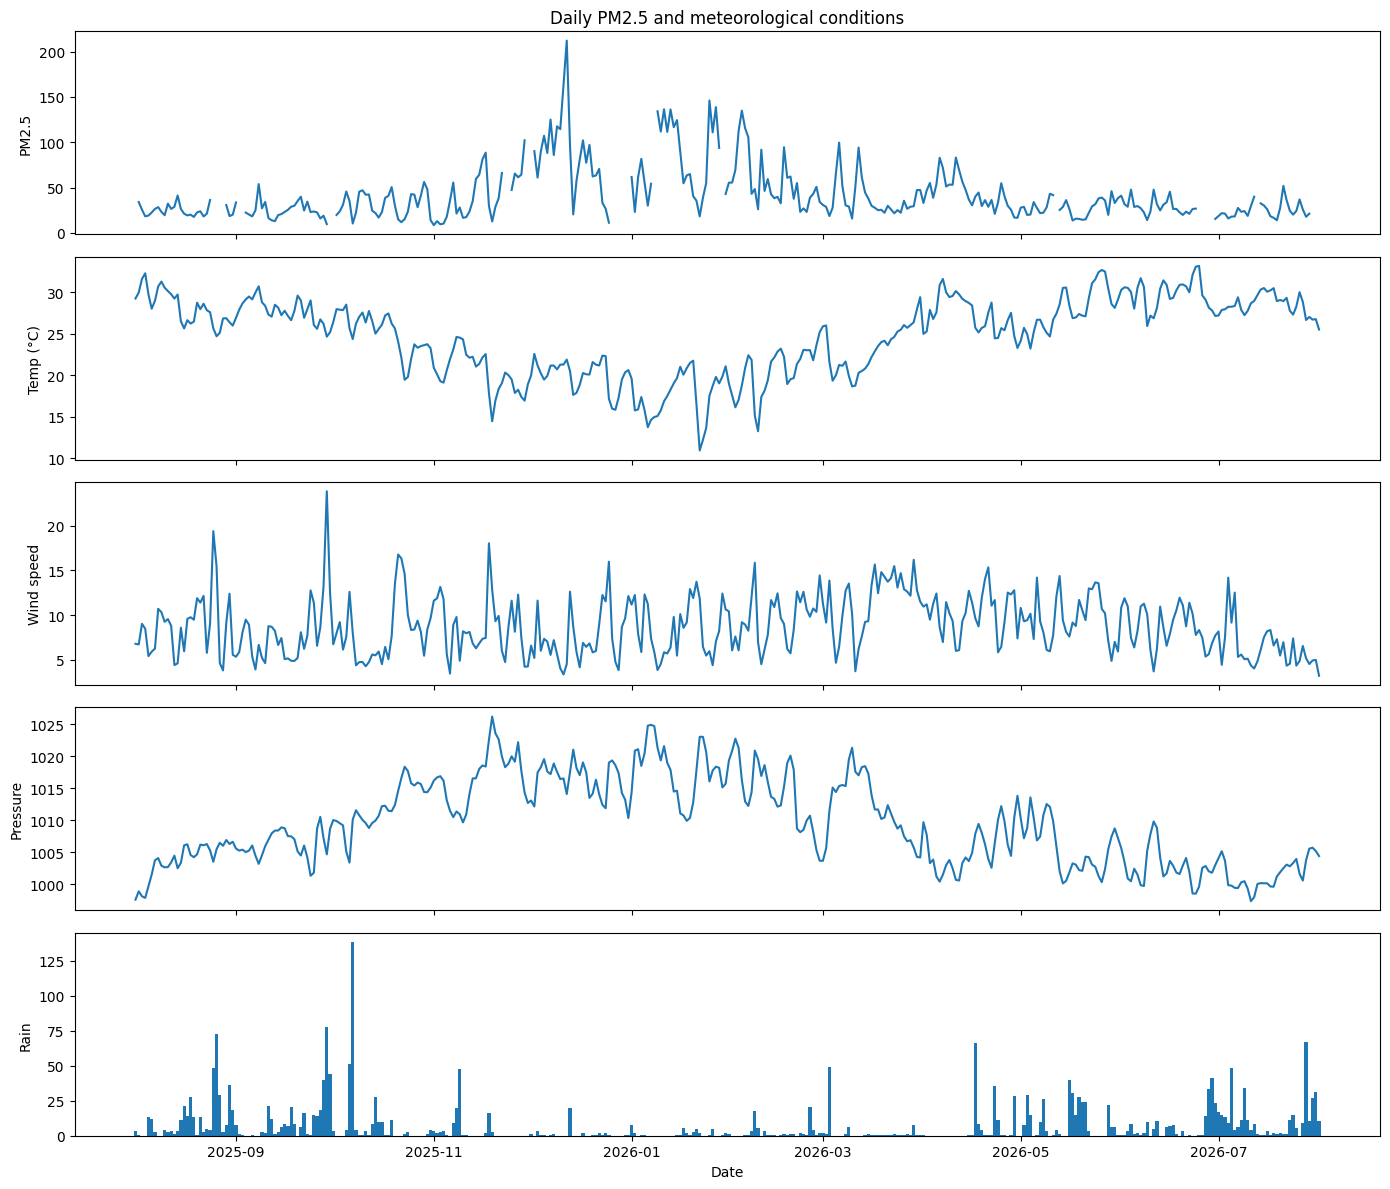

In [39]:
fig, axes = plt.subplots(
    nrows=5,
    ncols=1,
    figsize=(14, 12),
    sharex=True
)

# 1. PM2.5
axes[0].plot(daily_eda.index, daily_eda["pm25_mean_valid"])
axes[0].set_ylabel("PM2.5")
axes[0].set_title("Daily PM2.5 and meteorological conditions")

# 2. Temperature
axes[1].plot(daily_eda.index, daily_eda["temperature_mean"])
axes[1].set_ylabel("Temp (°C)")

# 3. Wind speed
axes[2].plot(daily_eda.index, daily_eda["wind_speed_mean"])
axes[2].set_ylabel("Wind speed")

# 4. Surface pressure
axes[3].plot(daily_eda.index, daily_eda["surface_pressure_mean"])
axes[3].set_ylabel("Pressure")

# 5. Precipitation
axes[4].bar(daily_eda.index, daily_eda["precipitation_total"], width=1.0)
axes[4].set_ylabel("Rain")
axes[4].set_xlabel("Date")

plt.tight_layout()
plt.show()

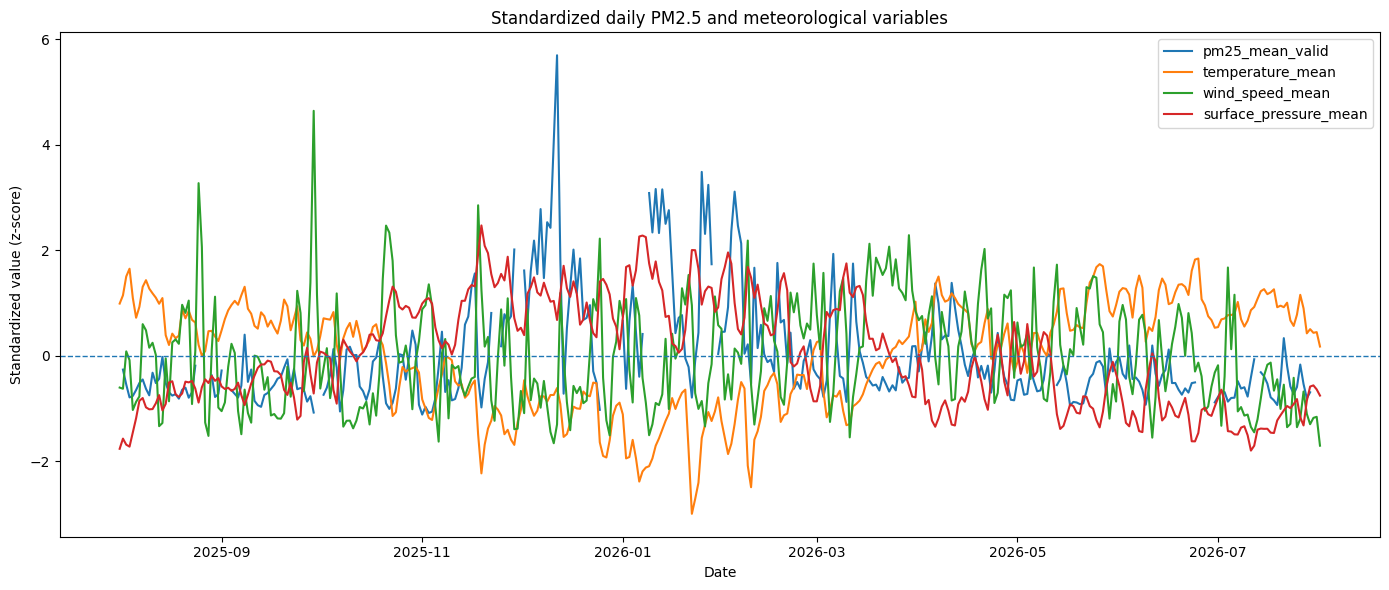

In [40]:
overlay_cols = [
    "pm25_mean_valid",
    "temperature_mean",
    "wind_speed_mean",
    "surface_pressure_mean"
]

daily_overlay = daily_eda[overlay_cols].copy()

for col in overlay_cols:
    mean = daily_overlay[col].mean()
    std = daily_overlay[col].std()
    daily_overlay[col] = (daily_overlay[col] - mean) / std

plt.figure(figsize=(14, 6))

for col in overlay_cols:
    plt.plot(daily_overlay.index, daily_overlay[col], label=col)

plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Standardized daily PM2.5 and meteorological variables")
plt.xlabel("Date")
plt.ylabel("Standardized value (z-score)")
plt.legend()
plt.tight_layout()
plt.show()